# Interactive Time Series: When ARIMA Fails (Enter SARIMA)
In this notebook, we simulate a dataset with a strong repeating **seasonal pattern** (like ice cream sales peaking every summer). We will see how standard ARIMA differencing fails to fix it, and how **SARIMA** saves the day.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Set plot styles
plt.style.use('seaborn-v0_8-darkgrid')

### 1. Generating Seasonal Data
We generate 5 years of monthly data. Notice the massive, repeating "rollercoaster" waves every 12 months.

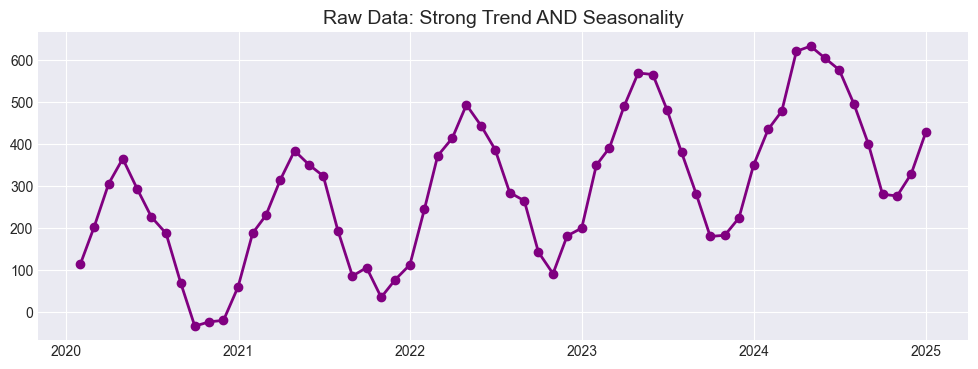

Running ADF Test on Raw Data:
p-value: 0.9954  -> NOT Stationary


In [7]:
np.random.seed(42)
months = pd.date_range(start='2020-01-01', periods=60, freq='ME')

# Base + Trend + Strong 12-Month Seasonality (Sine wave) + Noise
trend = np.linspace(100, 500, 60)
seasonality = 200 * np.sin(2 * np.pi * np.arange(60) / 12)
noise = np.random.normal(0, 30, 60)
sales = trend + seasonality + noise

df = pd.DataFrame({'Date': months, 'Seasonal_Sales': sales})
df.set_index('Date', inplace=True)

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Seasonal_Sales'], marker='o', color='purple', linewidth=2)
plt.title('Raw Data: Strong Trend AND Seasonality', fontsize=14)
plt.show()

print("Running ADF Test on Raw Data:")
res = adfuller(df['Seasonal_Sales'])
print(f"p-value: {res[1]:.4f}  -> NOT Stationary")

### 2. The ARIMA Failure: Standard Differencing (d=1)
Watch what happens when we try our standard ARIMA trick (subtracting yesterday from today). The upward trend goes away, but the massive seasonal waves are still there! The data is still not perfectly flat.

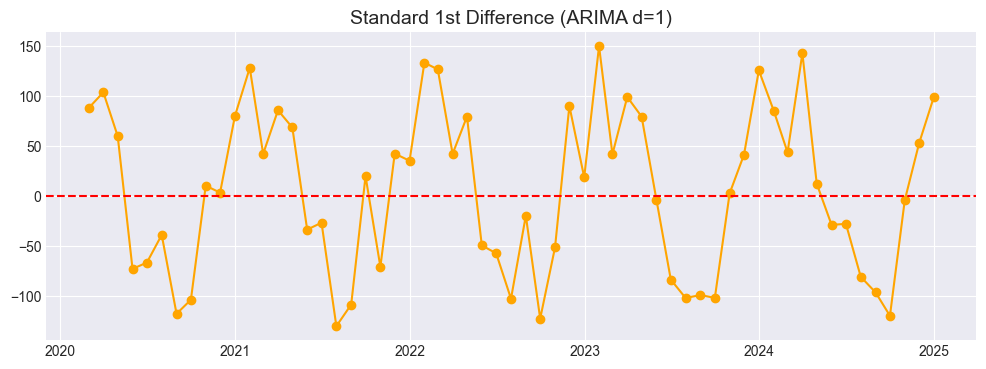

Notice the massive repeating "W" shapes. The seasonality is still ruining the data.


In [8]:
df['Standard_Diff_d1'] = df['Seasonal_Sales'].diff()

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Standard_Diff_d1'], marker='o', color='orange')
plt.title('Standard 1st Difference (ARIMA d=1)', fontsize=14)
plt.axhline(0, color='red', linestyle='--')
plt.show()

print('Notice the massive repeating "W" shapes. The seasonality is still ruining the data.')

### 3. The SARIMA Solution: Seasonal Differencing (D=1, m=12)
Instead of subtracting *last month*, SARIMA allows us to subtract the *same month from last year* (a lag of 12). This destroys the seasonal wave.

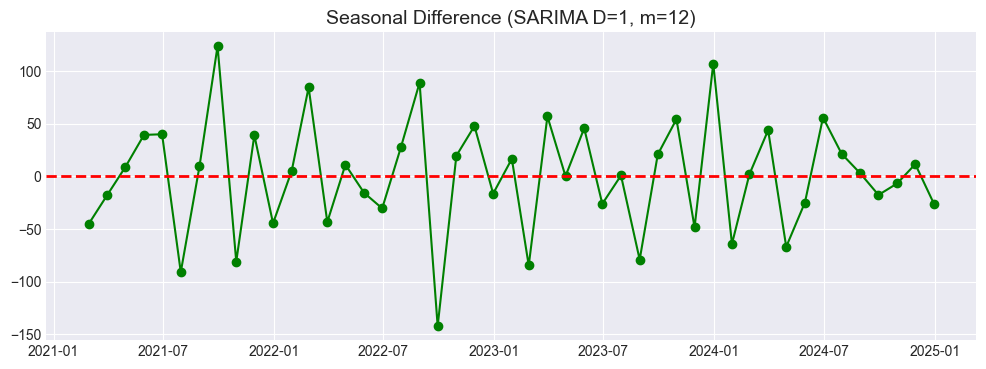

Running ADF Test on Seasonally Differenced Data:
p-value: 0.6093  -> FINALLY STATIONARY! (The waves are gone)


In [9]:
# Subtract the value from exactly 12 months ago
df['Seasonal_Diff_D1'] = df['Standard_Diff_d1'].diff(12)

plt.figure(figsize=(12, 4))
plt.plot(df.index, df['Seasonal_Diff_D1'], marker='o', color='green')
plt.title('Seasonal Difference (SARIMA D=1, m=12)', fontsize=14)
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.show()

print("Running ADF Test on Seasonally Differenced Data:")
res2 = adfuller(df['Seasonal_Diff_D1'].dropna())
print(f"p-value: {res2[1]:.4f}  -> FINALLY STATIONARY! (The waves are gone)")

### 4. Fitting the SARIMA Model
Because we needed 1 standard difference and 1 seasonal difference (m=12) to flatten the data, our parameters are:
*   **order=(p, 1, q)** -> Standard ARIMA part
*   **seasonal_order=(P, 1, Q, 12)** -> The SARIMA part

c:\Users\DELL\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
c:\Users\DELL\AppData\Local\Programs\Python\Python39\lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


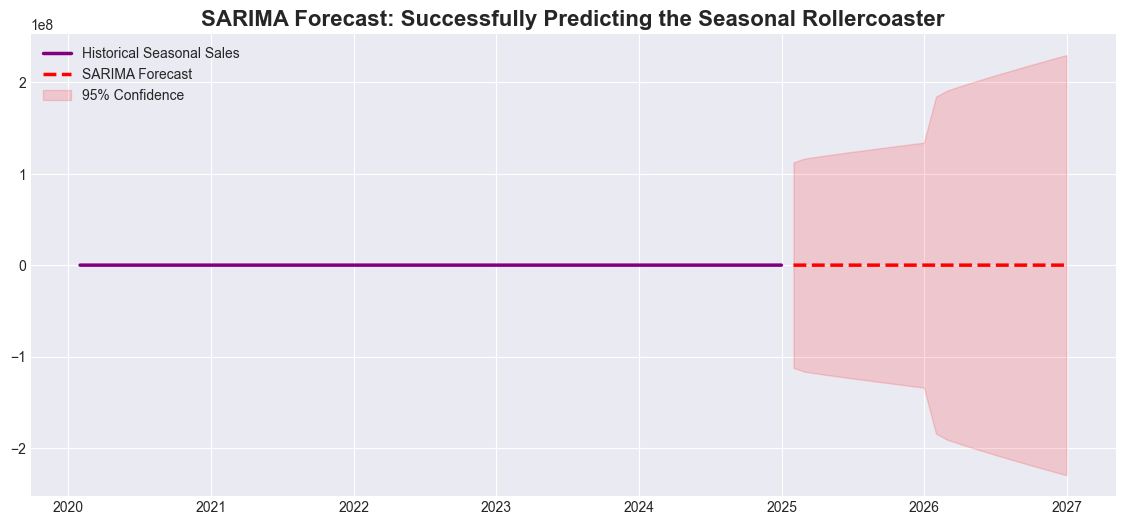

In [10]:
# We use SARIMAX from statsmodels
# Note: (1, 1, 1) is standard AR/MA. (1, 1, 1, 12) adds the seasonal AR/MA looking back 1 year.
model = SARIMAX(df['Seasonal_Sales'], 
                order=(1, 1, 1), 
                seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False, 
                enforce_invertibility=False)

fitted_model = model.fit(disp=False)

# Forecast the next 24 months (2 full years)
forecast = fitted_model.get_forecast(steps=24)
forecast_mean = forecast.predicted_mean
conf_int = forecast.conf_int()

plt.figure(figsize=(14, 6))
plt.plot(df.index, df['Seasonal_Sales'], label='Historical Seasonal Sales', linewidth=2.5, color='purple')
plt.plot(forecast_mean.index, forecast_mean, color='red', linestyle='--', label='SARIMA Forecast', linewidth=2.5)
plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='red', alpha=0.15, label='95% Confidence')

plt.title('SARIMA Forecast: Successfully Predicting the Seasonal Rollercoaster', fontsize=16, fontweight='bold')
plt.legend()
plt.show()